# Limpieza y estructura de los datos

Este notebook muestra de dónde salen los datos de la tesis, cómo se limpiaron y cómo quedaron
organizados en los paneles que usan los tres modelos. No descarga nada: lee los archivos que dejó
cada paso, copiados sin cambios en `datos/`. El código que los arma son los scripts
`1_descargar.py` a `2h_panel_lstm_bloques.py` de la raíz del repositorio, y cada decisión está
explicada con más detalle en `docs/DOCUMENTACION.md` y `docs/PANEL_HORARIO.md`.

| Paso | Script | Qué hace | Archivo que deja |
|---|---|---|---|
| 1 | `1_descargar.py` y `1b_ideam.py` | baja las series de cada fuente | carpeta `datos/` de la raíz (no está en git) |
| 2 | `2_construir_panel.py` | lleva cada serie a un valor por día | `panel_diario.csv` |
| 2b | `2b_panel_horario.py` | arma una fila por día y hora | `panel_horario_completo.csv.gz` (no está en git) |
| 2c | `2c_caracteristicas_horarias.py` | transforma cada variable con una regla fija | `panel_caracteristicas.csv.gz` |
| 2d | `2d_seleccion_variables.py` | elige las columnas de XGBoost en cada horizonte | `panel_horario_modelo.csv.gz` |
| 2e a 2h | `2e_panel_lstm.py` a `2h_panel_lstm_bloques.py` | pone cada variable en la fecha en que se publica | `panel_lstm_bloques.csv.gz` |

SARIMAX y XGBoost leen `panel_horario_modelo.csv.gz` y la LSTM lee `panel_lstm_bloques.csv.gz`. El
análisis de los datos está en `0b_datos_analisis.ipynb`.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# pandas 2.3 con numpy 2.5 avisa por una unidad interna de las fechas; no cambia nada
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

RAIZ = Path("datos")
PANELES = RAIZ / "paneles"
SONDEOS = RAIZ / "sondeos"

plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.titlelocation": "left",
                     "axes.titlesize": 11, "legend.frameon": False})
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)

## 1. Fuentes

Las series salen de seis fuentes públicas y de un listado de plantas que se bajó a mano.

| Fuente | Qué trae | Cómo se baja |
|---|---|---|
| XM | precio, demanda, generación, disponibilidad, ofertas, hidrología, contratos y cargos regulados | librería `pydataxm`, por tramos de 30 días |
| SIMEM | costo marginal del despacho y del redespacho, pronóstico de demanda del CND | servicio público de datos de SIMEM |
| NOAA, Climate Prediction Center | temperatura semanal del Pacífico en las regiones Niño, ONI y RONI | archivos de texto |
| Open-Meteo, reanálisis ERA5 | lluvia diaria en ocho puntos, uno por cuenca de los embalses grandes | API de archivo histórico, desde 2000 |
| datos.gov.co | TRM | conjunto `32sa-8pi3` |
| IDEAM | predicción de lluvia por región y alertas | boletines en PDF |
| XM, PARATEC | listado de plantas con su tecnología, combustible y tipo de despacho | a mano |

Tres decisiones de la descarga:

- Los códigos de métrica de XM se comprobaron uno por uno: se pidieron a la API días que ya estaban
  descargados y se verificó que los valores coincidieran.
- Al actualizar se vuelve a pedir el último mes, porque XM corrige las liquidaciones provisionales
  durante varias semanas.
- El listado de plantas se baja a mano porque el de la API solo trae las activas. Sin las retiradas
  se pierden 34 plantas, entre ellas Jepírachi, que fue la única eólica del país hasta 2023.

## 2. Qué tan completa quedó la descarga

Después de descargar se revisa cada serie: desde y hasta qué día llega y cuántos días le faltan en
el medio. La tabla es la de la descarga del 9 de octubre de 2026
(`datos/sondeos/auditoria_cobertura.csv`). Los faltantes no son todos iguales; para verlos por
tipo, aquí se clasifican con reglas simples:

In [2]:
cobertura = pd.read_csv(SONDEOS / "auditoria_cobertura.csv", parse_dates=["desde", "hasta"])
print(cobertura["fuente"].value_counts().to_string())


def tipo_de_faltante(f):
    if f["filas"] < 200:
        return "mensual"
    if f["desde"] > pd.Timestamp("2015-03-01"):
        return "empieza tarde"
    if f["dias_faltantes"] > 100:
        return "eventos"
    if f["dias_faltantes"] > 0:
        return "huecos sueltos"
    return "completa"


def lista(nombres, n=4):
    if len(nombres) <= n + 2:
        return ", ".join(nombres)
    return ", ".join(nombres.head(n)) + f" y {len(nombres) - n} más"


cobertura["tipo"] = cobertura.apply(tipo_de_faltante, axis=1)
(cobertura.groupby("tipo")["serie"].agg(series="size", cuales=lista)
 .loc[["completa", "eventos", "mensual", "huecos sueltos", "empieza tarde"]])

fuente
xm       65
simem     7


,series,cuales
tipo,,
completa,42,"aportes_media_hist, aportes_pct_rio, aportes_pct_sistema, aportes_por_rio y 38 más"
eventos,10,"compras_tie, dem_no_atendida_nop, demanda_no_atendida, exportaciones y 6 más"
mensual,6,"cee, cere, demanda_upme_alto, demanda_upme_bajo, demanda_upme_medio, mc"
huecos sueltos,6,"aportes_caudal, aportes_caudal_medio, demanda_max_potencia, gen_programada, gen_seguridad, precio_oferta_desp"
empieza tarde,8,"precio_esca_act, precio_esca_inf, precio_esca_marg, precio_esca_sup y 4 más"


Las que empiezan tarde son las variantes del precio de escasez y cuatro conjuntos de SIMEM:

In [3]:
tarde = cobertura.loc[cobertura["tipo"] == "empieza tarde", ["fuente", "serie", "desde"]]
tarde.assign(desde=tarde["desde"].dt.date).set_index("serie")

,fuente,desde
serie,,
precio_esca_act,xm,2017-12-01
precio_esca_inf,xm,2025-03-01
precio_esca_marg,xm,2017-12-01
precio_esca_sup,xm,2025-03-01
bandera_arranque,simem,2021-01-01
bandera_parada,simem,2021-01-01
holgura_horaria,simem,2021-01-01
reserva_caliente,simem,2024-09-02


Cada tipo se trata distinto:

| Tipo | Qué pasa | Cómo se trata |
|---|---|---|
| Completa | no le falta ningún día | nada |
| Eventos | XM no publica fila cuando el evento no ocurre: un día sin vertimientos o sin importaciones no aparece | el hueco es un 0, una imputación con valor fijo (Galli, sección 5) |
| Mensual | un valor por mes, que rige hasta que sale el siguiente | se repite en cada día del mes |
| Huecos sueltos | de uno a siete días sin dato | se repite el último valor conocido de la misma hora, que solo mira hacia atrás (decisión del autor) |
| Empieza tarde | la serie arranca entre 2017 y 2024 | no entra: un modelo que arranca en 2015 no la puede usar |

Las técnicas de imputación con la media o con vecinos cercanos están pensadas para huecos al azar.
Usarlas en una variable que todavía no existía sería inventar historia.

En los eventos el supuesto se puede comprobar. Si un hueco quiere decir que no pasó nada, la serie
nunca debería valer 0 en los días publicados. En el panel diario, que todavía no rellena nada,
ninguna de estas series tiene un cero en once años:

In [4]:
diario = pd.read_csv(PANELES / "panel_diario.csv", parse_dates=["fecha"], index_col="fecha")
eventos = ["vertimientos", "vertido_embalse", "importaciones", "exportaciones", "compras_tie",
           "demanda_no_atendida"]
pd.DataFrame({"días sin dato (%)": 100 * diario[eventos].isna().mean(),
              "días en 0": (diario[eventos] == 0).sum()}).round(1)

,días sin dato (%),días en 0
vertimientos,37.4,0
vertido_embalse,36.3,0
importaciones,13.8,0
exportaciones,9.6,0
compras_tie,18.7,0
demanda_no_atendida,59.8,0


La figura muestra el porcentaje de días sin dato por año en algunas series de cada tipo, ya en el
panel diario. Las de eventos tienen huecos en casi todos los años; las que empiezan tarde
están vacías antes de su primer dato. El precio de escasez de activación, además, no tiene datos
de marzo de 2025 a abril de 2026.

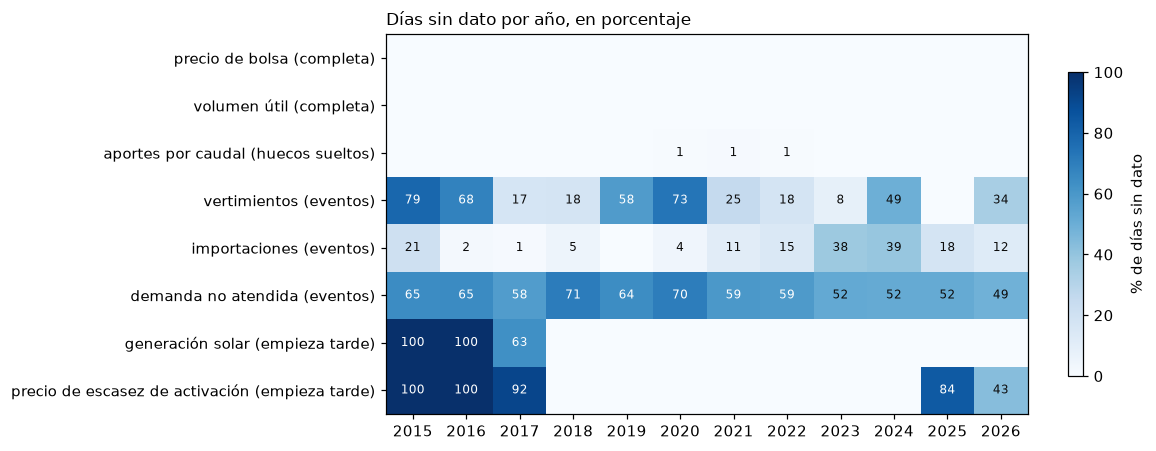

In [5]:
ejemplos = {"precio de bolsa (completa)": "precio_bolsa", "volumen útil (completa)": "volumen_util_pct",
            "aportes por caudal (huecos sueltos)": "aportes_caudal", "vertimientos (eventos)": "vertimientos",
            "importaciones (eventos)": "importaciones", "demanda no atendida (eventos)": "demanda_no_atendida",
            "generación solar (empieza tarde)": "gen_solar",
            "precio de escasez de activación (empieza tarde)": "precio_esca_act"}
hasta_precio = diario.loc[:"2026-10-06", list(ejemplos.values())]
faltan = 100 * hasta_precio.isna().groupby(hasta_precio.index.year).mean().T

fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(faltan.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
for i in range(faltan.shape[0]):
    for j in range(faltan.shape[1]):
        v = faltan.iat[i, j]
        if v >= 0.5:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 55 else "#0b0b0b")
ax.set_xticks(range(faltan.shape[1]), faltan.columns)
ax.set_yticks(range(faltan.shape[0]), list(ejemplos))
ax.set_title("Días sin dato por año, en porcentaje")
fig.colorbar(im, ax=ax, shrink=0.8, label="% de días sin dato")
plt.tight_layout()
plt.show()

## 3. Un valor por día: el panel diario

XM entrega cada serie en uno de tres formatos: un valor por día para todo el sistema, un valor por
día para cada río, embalse o planta, o 24 valores por día para cada planta. Para llegar a un número
por día se decidió cómo juntar las plantas y las horas según lo que mide la serie
(`2_construir_panel.py`):

| Qué mide | Entre plantas | Entre horas | Ejemplos |
|---|---|---|---|
| Energía, que es un flujo | suma | suma | generación, demanda, importaciones |
| Capacidad o disponibilidad, que es un nivel | suma | promedio | disponibilidad declarada |
| Precio | promedio | promedio | precio de bolsa, costo marginal |
| Porcentaje por embalse | promedio ponderado por la capacidad | | volumen útil |

Además:

- El ONI de un mes se publica dos meses después, porque necesita el mes siguiente para cerrar su
  promedio de tres meses. Se corre dos meses para no usarlo antes de tiempo.
- Un día con filas pero sin ningún valor queda vacío, no en 0.
- XM publica la demanda de los últimos días a medias mientras llegan las mediciones. Un día cuya
  demanda es menos de la mitad de la mediana de los 28 días anteriores se deja vacío; desde 2015
  solo pasó el 5 y el 6 de octubre de 2026, ni siquiera en la cuarentena de 2020. Por la misma
  razón, la obligación de energía en firme se deja vacía los días en que llega toda en 0.
- Se calculan variables que no vienen hechas: la generación por tecnología y por combustible,
  cruzando la generación de cada planta con el listado de PARATEC; la concentración del mercado; el
  perfil del precio dentro del día y la forma de la curva de ofertas.

In [6]:
print(f"{diario.shape[0]:,} días x {diario.shape[1]} columnas, del {diario.index.min().date()} "
      f"al {diario.index.max().date()}")
ultimos = diario.loc["2026-10-01":"2026-10-09"]
pd.DataFrame({"precio (COP/kWh)": ultimos["precio_bolsa"],
              "demanda real (GWh)": ultimos["demanda_real"] / 1e6,
              "generación (GWh)": ultimos["gen_total_sistema"],
              "energía en firme (GWh)": ultimos["oblig_energia_firme"] / 1e6,
              "volumen útil (%)": 100 * ultimos["volumen_util_pct"],
              "costo marginal programado (COP/kWh)": ultimos["costo_marginal_prog"]}).round(1)

4,300 días x 171 columnas, del 2015-01-01 al 2026-10-09


,precio (COP/kWh),demanda real (GWh),generación (GWh),energía en firme (GWh),volumen útil (%),costo marginal programado (COP/kWh)
fecha,,,,,,
2026-10-01,751.6,250.0,253.2,278.3,76.1,483.0
2026-10-02,814.8,251.1,254.4,275.8,76.2,467.7
2026-10-03,661.1,231.5,234.0,263.4,76.3,520.9
2026-10-04,641.4,213.5,215.9,243.2,76.2,343.0
2026-10-05,652.3,NaN,249.3,NaN,75.2,400.3
2026-10-06,591.8,NaN,249.7,NaN,74.9,385.8
2026-10-07,NaN,NaN,NaN,NaN,74.8,431.2
2026-10-08,NaN,NaN,NaN,NaN,74.8,562.0
2026-10-09,NaN,NaN,NaN,NaN,NaN,487.7


Los últimos días del panel muestran las reglas en acción. La demanda y la energía en firme del 5 y
el 6 de octubre quedaron vacías, aunque la generación de esos días es normal. Y cada serie llega
hasta un día distinto: el precio, hasta el 6; el volumen útil, hasta el 8, y el costo marginal
programado, hasta el 9. Eso es lo que se mide en la sección siguiente.

## 4. Una fila por día y hora

El paso 2b arma una fila por día y hora con lo que cambia dentro del día (precio, demanda,
generación, disponibilidad, ofertas y costo marginal) y le agrega, repetidas en las 24 horas, las
variables que solo existen por día (hidrología, lluvia, El Niño y cargos regulados). La hora sigue
la convención de XM: la hora 1 va de 0:00 a 1:00. En ese paso también se corrigen dos problemas de
SIMEM: su hora empieza una hora antes que la de XM, y en 70 días traía además el total nacional
como si fuera un mercado más, lo que duplicaba el pronóstico de demanda.

Cada fila es un día $t$ y una hora $H$, y se para al cierre del día $t$: en ella está lo que se
conocía ese día. El objetivo es el cambio en logaritmo frente al precio del día $t$ a la misma hora,

$$y_h = \ln P(t+h,\,H) - \ln P(t,\,H),$$

así que el precio de la misma hora $h$ días después está $24h$ filas más abajo. El panel horario
completo no está en git; aquí se lee su versión final, `panel_horario_modelo.csv.gz`, y se
comprueba su estructura:

In [7]:
modelo = pd.read_csv(PANELES / "panel_horario_modelo.csv.gz", parse_dates=["fecha"])
modelo = modelo.sort_values(["fecha", "hora"]).reset_index(drop=True)
print(f"{len(modelo):,} filas x {modelo.shape[1]} columnas, del {modelo['fecha'].min().date()} "
      f"al {modelo['fecha'].max().date()}")
print("horas por día:", modelo.groupby("fecha").size().unique())
print("horas sin precio:", modelo["precio"].isna().sum())

# el promedio de las 24 horas reproduce el precio del panel diario
dif = (modelo.groupby("fecha")["precio"].mean() - diario["precio_bolsa"]).abs().max()
print(f"diferencia máxima con el precio diario: {dif:.4f} COP/kWh")

# y_h3 es el logaritmo del precio 72 filas más abajo menos el de la fila
dif = (modelo["lp"].shift(-72) - modelo["lp"] - modelo["y_h3"]).abs().max()
print(f"diferencia máxima al rearmar y_h3: {dif:.5f}")

101,712 filas x 118 columnas, del 2015-03-01 al 2026-10-06
horas por día: [24]
horas sin precio: 0
diferencia máxima con el precio diario: 0.0045 COP/kWh
diferencia máxima al rearmar y_h3: 0.00001


In [8]:
modelo.loc[modelo["fecha"] == "2024-03-01", ["fecha", "hora", "bloque", "precio", "lp", "dia_semana",
                                             "es_festivo", "y_h3", "y_h4"]].head(5)

,fecha,hora,bloque,precio,lp,dia_semana,es_festivo,y_h3,y_h4
78912,2024-03-01,1,prueba_A,469.075,6.151,4,0,-0.111,0.075
78913,2024-03-01,2,prueba_A,469.075,6.151,4,0,-0.111,0.061
78914,2024-03-01,3,prueba_A,469.075,6.151,4,0,-0.111,0.023
78915,2024-03-01,4,prueba_A,408.946,6.014,4,0,0.002,0.160
78916,2024-03-01,5,prueba_A,469.075,6.151,4,0,-0.111,0.023


### Cuándo se publica cada dato

El precio de bolsa sale con dos días de atraso. Con datos hasta el día $t$, el pronóstico se hace
el día $R = t + 2$ y la semana que se pronostica va de $t + 3$ a $t + 9$, es decir, $h = 3$ a $9$.
Las demás series no salen todas al tiempo. El 10 de octubre de 2026 se le pidió a la API de XM el
último día disponible de cada métrica (`datos/sondeos/publicacion_metricas_horarias.csv`):

In [9]:
publicacion = pd.read_csv(SONDEOS / "publicacion_metricas_horarias.csv")
usadas = publicacion[publicacion["la_uso"] == "sí"].dropna(subset=["atraso_dias"]).copy()
# los nombres de XM terminan en "por Sistema" o "por Recurso", a veces cortados
usadas["nombre"] = usadas["nombre"].str.replace(r"\s+(por\s+)?(Sistema|Sistem|Siste|Recurso)$", "", regex=True)
usadas["atraso_dias"] = usadas["atraso_dias"].astype(int)
# el precio de bolsa de primero en su grupo
usadas["es_precio"] = usadas["nombre"].str.startswith("Precio Bolsa")
usadas = usadas.sort_values(["atraso_dias", "es_precio"], ascending=[True, False])
(usadas.groupby("atraso_dias")["nombre"].agg(métricas="size", cuales=lambda s: lista(s, 3))
 .rename_axis("días de atraso"))

,métricas,cuales
días de atraso,,
0,6,"Costo Marginal Despacho Programado, Disponibilidad Declarada, Disponibilidad Real y 3 más"
2,14,"Precio Bolsa Nacional, Consumo Combustible MBTU, Demanda Comercial y 11 más"
5,7,"Compras Bolsa TIE Energía, Compras en Contrato Energía, Perdidas de Energía y 4 más"
10,1,Precio de Oferta de Despacho


El despacho programado y la disponibilidad declarada del día salen antes que el precio; la demanda
y la generación salen con él; los contratos, las pérdidas y las restricciones, tres días después, y
las ofertas de las plantas, ocho días después. En el panel de XGBoost y SARIMAX, lo que sale después
del precio entra con ese atraso adicional. Lo que sale antes se aprovecha en el panel de la LSTM
(sección 8).

Cada panel tiene una prueba de fuga, que corre cada vez que se arma: se alteran los datos crudos
posteriores a un día y se arma todo de nuevo. Ninguna fila anterior a ese día puede cambiar.

## 5. Variables base: una regla fija para cada una

El paso 2c deja una columna por variable, ya transformada y sin rezagos. No mira el objetivo ni
hace pruebas: cada variable se transforma con una regla fija según lo que mide.

- Los precios y las ofertas van en logaritmo (Galli, sección 11).
- Las cantidades que crecen con el sistema van como fracción: las horarias, de la demanda o la
  generación de esa hora; las diarias, de la media móvil de 7 días de la demanda diaria, que solo
  mira hacia atrás y no mete el ruido de domingos y festivos (Galli, sección 17).
- Porcentajes, índices y clima van tal cual.
- Una variable queda fuera si le falta más de 1% de los días desde marzo de 2015 o si no varía.

In [10]:
variables = pd.read_csv(PANELES / "panel_caracteristicas_variables.csv", index_col="variable")
print(f"{len(variables)} variables base, {variables['entra'].sum()} entran")
variables.loc[~variables["entra"], ["grupo", "tipo", "faltante_pct", "motivo"]]

136 variables base, 134 entran


,grupo,tipo,faltante_pct,motivo
variable,,,,
vol_pct_el_quimbo,embalses,diaria,5.781,más de 1% de faltantes
pred_lluvia_pacifica,ideam,diaria,3.209,más de 1% de faltantes


In [11]:
entran = variables[variables["entra"]]
pd.crosstab(entran["grupo"], entran["tipo"], margins=True, margins_name="total")

tipo,diaria,horaria,precio,total
grupo,,,,
aportes,7,0,0,7
costo_marginal,0,3,0,3
curva_de_merito,0,6,0,6
curva_del_dia,10,0,0,10
demanda,0,4,0,4
disponibilidad,0,4,0,4
el_nino,11,0,0,11
embalses,10,0,0,10
generacion,0,13,0,13


Las reglas más usadas, y cuatro variables que combinan dos fuentes (decisiones del autor):

In [12]:
entran["regla"].value_counts().head(6).rename_axis("regla").to_frame("variables")

,variables
regla,
tal cual,58
log,16
fracción de la generación,6
fracción de la generación del día (0 si no hubo),6
sobre la demanda,6
GWh sobre la media de 7 días de la demanda diaria,5


In [13]:
entran.loc[["brecha_escasez", "error_cmg_despacho", "presion_hidro_horaria", "dias_autonomia"],
           ["grupo", "fuente", "regla"]]

,grupo,fuente,regla
variable,,,
brecha_escasez,interaccion,"precio_bolsa, precio_escasez",lp - log(precio de escasez): distancia al techo
error_cmg_despacho,interaccion,"precio_bolsa, cmg_despacho",lp - log(costo marginal programado): el error del operador
presion_hidro_horaria,interaccion,"demanda_comercial, aportes_por_rio",demanda de la hora / aportes del día por hora
dias_autonomia,embalses,"volumen_por_embalse, demanda_comercial",volumen útil (GWh) sobre la media de 7 días de la demanda diaria


Antes del filtro quedaron fuera, por diseño, las alertas del IDEAM (tienen ceros falsos en
2019-2021), las variantes del precio de escasez, los cargos mensuales y las proyecciones de la
UPME, las series que empiezan tarde, y las descargas y el vertido por embalse, porque el número de
embalses que los reporta cambia de un día a otro.

El panel también trae el calendario del día $t$ y del día que se pronostica (día de la semana y
festivo), tal cual y como seno y coseno, para que la hora 24 quede cerca de la hora 1 y el domingo
cerca del lunes (Galli, sección 15).

## 6. Columnas derivadas

`features.py` arma, a partir de cada variable base, rezagos, medias móviles, tendencias y medidas
de variabilidad, siempre con datos hasta el cierre del día $t$. Una ventana se calcula solo si
tiene al menos 75% de sus datos, para que un hueco suelto no borre un mes de medias. Los rezagos
del precio de 1, 2, 3 y 7 días vienen del modelo LEAR (Lago et al., 2021) y las medias de día,
semana y mes, del modelo HAR (Corsi, 2009). Los de 14, 21 y 28 días se agregaron por el ciclo
semanal del precio.

In [14]:
entran.groupby("tipo")["columnas_derivadas"].agg(variables="size", columnas="sum")

,variables,columnas
tipo,,
diaria,89,890
horaria,44,928
precio,1,43


El precio tiene 43 columnas derivadas; cada variable horaria, 21 (22 si tiene versión del día
siguiente) y cada diaria, 10. En total son 1.861 columnas candidatas.

## 7. Las columnas de XGBoost (paso 2d)

De las 1.861 columnas se eligen, para cada horizonte, las que entran a XGBoost, en tres etapas:
limpieza y orden con 2015-2019, y cuántas columnas con 2020-2022. El orden y el número de columnas
están en `2_xgboost.ipynb`. Aquí se ve la limpieza, que depende solo de los datos:

- Casi constantes: un mismo valor en 99% de las horas o más (Naik, cuaderno 1).
- Inestables: más de 25% de sus valores de 2018-2019 quedan fuera del rango de 2015-2017. Son
  niveles que se corren con el tiempo, y un árbol no extrapola.
- Niveles que siguen al dólar: el cargo por confiabilidad se fija en dólares (CREG 071 de 2006,
  art. 29), así que en pesos se mueve con la TRM. De él y de la TRM quedan solo los cambios.
- Redundantes: de cada grupo con correlación de Spearman mayor a 0,95 queda la más correlacionada
  con el objetivo (Naik, cuaderno 2).

In [15]:
columnas = pd.read_csv(PANELES / "panel_horario_modelo_columnas.csv")
candidatas = columnas[columnas["tipo"] != "fija"]
print(f"{len(candidatas):,} columnas candidatas")

MOTIVOS = [("casi constante", "casi constantes"), ("inestable", "inestables"),
           ("nivel que sigue", "siguen al dólar"), ("correlación", "redundantes"), ("pasa", "quedan")]


def motivo(texto):
    for clave, nombre in MOTIVOS:
        if str(texto).startswith(clave):
            return nombre


embudo = pd.DataFrame({f"h = {h}": candidatas[f"limpieza_h{h}"].map(motivo).value_counts()
                       for h in range(3, 8)}).loc[[n for _, n in MOTIVOS]]
embudo.loc["le ganan al ruido"] = [candidatas[f"orden_h{h}"].notna().sum() for h in range(3, 8)]
embudo.loc["entran"] = [candidatas[f"entra_h{h}"].sum() for h in range(3, 8)]
embudo

1,861 columnas candidatas


,h = 3,h = 4,h = 5,h = 6,h = 7
casi constantes,10,10,10,10,10
inestables,106,106,106,106,106
siguen al dólar,12,12,12,12,12
redundantes,444,443,442,443,444
quedan,1289,1290,1291,1290,1289
le ganan al ruido,15,43,89,99,117
entran,10,20,10,10,20


La limpieza deja unas 1.290 columnas en cada horizonte, y el paso de orden, que compara cada
columna con columnas de ruido, deja entre 15 y 117. Al final entran 10 o 20. Los horizontes 8 y 9
usan las columnas de $h = 7$.

El panel final, `panel_horario_modelo.csv.gz`, trae `fecha`, `hora`, `bloque`, el precio, su
logaritmo, el calendario, los objetivos y las 57 columnas que entraron en algún horizonte. `bloque`
marca la ventana de cada día. Se parte siempre por fechas, nunca por filas, porque las 24 horas de
un día comparten el estado del sistema:

In [16]:
ventanas = modelo.groupby("bloque")["fecha"].agg(desde="min", hasta="max", días="nunique")
ventanas["desde"] = ventanas["desde"].dt.date
ventanas["hasta"] = ventanas["hasta"].dt.date
ventanas.loc[["seleccion", "validacion", "prueba_A", "prueba_B"]]

,desde,hasta,días
bloque,,,
seleccion,2015-03-01,2019-12-31,1767
validacion,2020-01-01,2022-12-31,1096
prueba_A,2023-01-01,2025-12-31,1096
prueba_B,2026-01-01,2026-10-06,279


La selección sirve para elegir variables y órdenes, y la validación, para elegir configuraciones.
La prueba se usó una sola vez, con los modelos finales.

## 8. El panel de la LSTM: cada dato en la fecha en que se publica

En el panel de XGBoost todo se para en el día $t$ del último precio conocido. Pero el pronóstico
se hace el día $R = t + 2$, y para entonces hay datos más recientes que el precio: el despacho
programado del día $R$ sale la víspera, y los embalses y aportes de ayer ya están publicados. En el
panel de la LSTM (pasos 2e a 2h), la fila del día $t$ trae de cada variable el último dato que
estaba publicado en $R$ (decisión del autor, con los atrasos medidos en los sondeos de la sección
4).

La columna `dias_frente_al_precio` dice de qué día es el dato de cada variable: $-2$ es el día
$R$, dos días más reciente que el precio; $-1$ es el día anterior a $R$; $0$ es el día $t$, como el
precio, y un número positivo es un dato más viejo que el precio.

In [17]:
bloques = pd.read_csv(PANELES / "panel_lstm_bloques_variables.csv", index_col="variable")
(bloques.groupby("dias_frente_al_precio")["grupo"]
 .agg(variables="size", grupos=lambda g: ", ".join(g.str.replace("_", " ").value_counts().index[:4])))

,variables,grupos
dias_frente_al_precio,,
-2,46,"lluvia, el nino, ideam, despacho de hoy"
-1,18,"aportes, embalses, despacho de ayer"
0,42,"mezcla por planta, generacion, sistema, demanda"
2,1,sistema
3,6,"red y contratos, sistema"
8,22,"ofertas, demanda"
38,1,sistema


Se puede comprobar con el panel diario. En la fila del día $t$, el costo marginal programado debe
ser el del día $t + 2$ y el volumen útil de los embalses, el del día $t + 1$. La tabla da el
porcentaje de días en que la fila coincide con el panel diario, con una diferencia menor a 0,1%:

In [18]:
lstm = pd.read_csv(PANELES / "panel_lstm_bloques.csv.gz", parse_dates=["fecha"])
print(f"{len(lstm):,} filas x {lstm.shape[1]} columnas")
por_dia = lstm.groupby("fecha").agg(cmg=("cmg_despacho", lambda x: np.exp(x).mean()),
                                    volumen=("volumen_util_pct", "first"))


def coincide(serie, otra, k):
    # porcentaje de días en que la fila t es igual al dato del día t + k
    x = otra.reindex(serie.index + pd.Timedelta(days=k)).to_numpy()
    ok = ~np.isnan(x) & serie.notna().to_numpy()
    return 100 * np.mean(np.isclose(serie.to_numpy()[ok], x[ok], rtol=0.001))


pd.DataFrame({f"día t + {k}": {"costo marginal programado": coincide(por_dia["cmg"], diario["costo_marginal_prog"], k),
                               "volumen útil": coincide(por_dia["volumen"], diario["volumen_util_pct"], k)}
              for k in range(3)}).round(1)

103,200 filas x 163 columnas


,día t + 0,día t + 1,día t + 2
costo marginal programado,2.3,3.1,96.7
volumen útil,14.7,100.0,14.7


En el costo marginal no llega a 100% porque el panel horario usa la serie de SIMEM y el diario la
de XM, que en algunos días difieren un poco.

Los huecos sueltos que quedan se llenan con el último valor conocido de la misma hora, que no trae
información del futuro. Las variables se agruparon en bloques según lo que dicen del mercado y
cuándo se publican. Los bloques 3 a 6 se probaron en la selección de la LSTM (`3_lstm.ipynb`) y
entraron el 3 y el 4:

In [19]:
(bloques[bloques["bloque"] > 0].sort_values(["bloque", "dias_frente_al_precio"])
 [["bloque", "nombre_bloque", "tipo", "dias_frente_al_precio"]])

,bloque,nombre_bloque,tipo,dias_frente_al_precio
variable,,,,
cmg_despacho,3,despacho de hoy,horaria,-2
disp_decl_hoy_rel,3,despacho de hoy,horaria,-2
cmg_hoy_vs_precio,3,despacho de hoy,horaria,-2
frac_termica_prog,3,despacho de hoy,horaria,-2
aportes_media_hist,4,estado hidrológico,diaria,-1
volumen_util_pct,4,estado hidrológico,diaria,-1
brecha_escasez,4,estado hidrológico,horaria,0
presion_hidro_horaria,4,estado hidrológico,horaria,0
dias_autonomia,4,estado hidrológico,diaria,0


## 9. Qué usa cada modelo

| Modelo | Panel | Qué toma |
|---|---|---|
| SARIMAX | `panel_horario_modelo.csv.gz` | el logaritmo del precio de cada hora y el festivo del día pronosticado |
| XGBoost | `panel_horario_modelo.csv.gz` | `lp`, el calendario y 10 o 20 columnas elegidas en cada horizonte |
| LSTM | `panel_lstm_bloques.csv.gz` | las 24 horas de `lp`, el calendario y las 9 variables de los bloques 3 y 4, en secuencias de 28 días |

Los tres pronostican lo mismo y en las mismas filas: $y_h$ para $h = 3$ a $9$ y las 24 horas de
cada día.

## Referencias

- Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of
  Financial Econometrics*, 7(2), 174-196.
- Galli, S. *Feature Engineering for Machine Learning*. Repositorio
  github.com/solegalli/feature-engineering-for-machine-learning. Secciones 5, 11, 15 y 17.
- Lago, J., Marcjasz, G., De Schutter, B. y Weron, R. (2021). Forecasting day-ahead electricity
  prices: A review of state-of-the-art algorithms, best practices and an open-access benchmark.
  *Applied Energy*, 293, 116983.
- Naik, K. *Complete-Feature-Selection*. Repositorio github.com/krishnaik06/Complete-Feature-Selection.
  Cuadernos 1 y 2.
- Resolución CREG 071 de 2006. Metodología del Cargo por Confiabilidad, art. 29.